# Step 3: Deep Feature Extraction & Transfer Learning for Anomaly Detection

## 1. Executive Summary

In this notebook, we explore the fundamental transition from **Reconstruction-Based Normality Modeling** (Convolutional Autoencoders & VAEs) to **Pre-trained Deep Feature Representation Learning** (ResNet Backbones).

### Core Problem & Motivation: The Generalization Paradox
As demonstrated in Week 1, reconstruction-based approaches suffer from an inherent dilemma:
1. If the decoder capacity is too low, normal reconstructions are overly blurred, generating noisy residual false alarms.
2. If the decoder capacity is too high, the network generalizes to reconstruct anomalous defect regions as well, eliminating the anomaly signal.

### The Transfer Learning Paradigm
Deep convolutional networks (e.g., ResNet-18 pre-trained on ImageNet-1K) already possess a rich hierarchy of spatial filters. Instead of training a model from scratch:
- We freeze the pre-trained backbone.
- We extract intermediate feature maps using non-invasive PyTorch forward hooks.
- We fuse multi-scale features (`layer2` local motifs + `layer3` contextual patterns) to form a spatial patch representation.
- We construct an offline **Memory Bank** of defect-free patch representations.
- At test time, anomaly scores are computed via Euclidean nearest-neighbor distances ($k$-NN).

---

## 2. Mathematical Formulations

### Multi-Scale Feature Alignment
For an input image $x \in \mathbb{R}^{3 	imes 224 	imes 224}$, we extract activations from intermediate residual blocks:
- $f_{\text{layer2}} \in \mathbb{R}^{128 	imes 28 	imes 28}$
- $f_{\text{layer3}} \in \mathbb{R}^{256 	imes 14 	imes 14}$

We align the spatial resolution via bilinear upsampling and concatenate along the channel axis:
$$f(p) = \left[ f_{\text{layer2}}(p) \;\parallel\; \text{Upsample}(f_{\text{layer3}}(p)) \right] \in \mathbb{R}^{384}$$
where $p \in \{1, \dots, 28 \times 28\}$ denotes the spatial patch index ($P = 784$ patches per image).

### Patch Anomaly Scoring via k-NN Distance
Given a normal memory bank $\mathcal{M} = \{m_i\}_{i=1}^{N_{\text{bank}}}$, the anomaly score of a test patch $p$ is defined as:
$$s(p) = \frac{1}{k} \sum_{j=1}^k \|f(p) - m_{(j)}\|_2$$
where $m_{(j)}$ is the $j$-th nearest neighbor in $\mathcal{M}$.

### Image-Level Anomaly Score
The image anomaly score is given by the maximum patch distance across the entire spatial grid:
$$S_{\text{image}} = \max_{p \in \{1, \dots, P\}} s(p)$$


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Dynamically resolve project root
current_path = Path.cwd().resolve()
PROJECT_ROOT = current_path
for p in [current_path, current_path.parent, current_path.parent.parent]:
    if (p / "src").exists() and (p / "data").exists():
        PROJECT_ROOT = p
        break

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from PIL import Image
from IPython.display import display

from src.models import (
    ResNetExtractor,
    FeatureMemoryBank,
    interpolate_and_smooth_anomaly_maps,
)
from src.data import get_mvtec_dataloader, MVTecDataset

# Styling and visualization defaults
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 120

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Execution Device:", device)
if torch.cuda.is_available():
    print("GPU Model:       ", torch.cuda.get_device_name(0))


Execution Device: cuda
GPU Model:        NVIDIA GeForce RTX 4050 Laptop GPU


## 3. ResNet Feature Hierarchy & Extraction Mechanics

In standard classification, only the final global average-pooled vector (1000-d) is utilized. For anomaly detection, however, spatial defect localization is paramount.

### Why Layer 2 and Layer 3?
| ResNet Layer | Spatial Resolution (224x224 input) | Channels | Receptive Field & Encoded Properties | Suitability for Anomaly Detection |
|---|---|---|---|---|
| `layer1` | $56 \times 56$ | 64 | Very small, edge detectors, primitive color transitions | Too low-level; high memory consumption |
| `layer2` | $28 \times 28$ | 128 | Medium, local textures, geometric corners, surface patterns | Optimal for surface defect detection |
| `layer3` | $14 \times 14$ | 256 | Large, structural components, shapes, object parts | Optimal for deformation/structural defects |
| `layer4` | $7 \times 7$ | 512 | Very large, semantic class-level abstractions | Too coarse; loses precise spatial defect boundaries |

By fusing `layer2` ($28 \times 28$) and bilinearly upsampled `layer3` ($28 \times 28$), each spatial location yields a **384-dimensional descriptor** that balances local texture sensitivity with structural semantic context.


In [2]:
# Initialize ResNetExtractor with ResNet-18 backbone
extractor = ResNetExtractor(
    backbone="resnet18",
    pretrained=True,
    layers=("layer2", "layer3"),
    patch_pooling=False,
    device=device,
).to(device)
extractor.eval()

# Verify tensor flow with synthetic input
dummy_input = torch.randn(2, 3, 224, 224, device=device)
with torch.no_grad():
    fused_features = extractor(dummy_input)

print("Extractor Backbone:      ", extractor.backbone_name)
print("Monitored Hook Layers:   ", extractor.layers)
print("Input Tensor Shape:      ", dummy_input.shape)
print("Fused Output Shape:      ", fused_features.shape)
print("Spatial Resolution:       28x28 grid (784 patches per image)")
print("Feature Dimension per Patch: 384 channels")


Extractor Backbone:       resnet18
Monitored Hook Layers:    ('layer2', 'layer3')
Input Tensor Shape:       torch.Size([2, 3, 224, 224])
Fused Output Shape:       torch.Size([2, 384, 28, 28])
Spatial Resolution:       28x28 grid (784 patches per image)
Feature Dimension per Patch: 384 channels


## 4. Multi-Layer Activation Map Visualization

To visualize how pre-trained deep representations respond to normal vs. anomalous regions, we compute the channel-wise $L_1$ activation energy across the spatial grid:

$$E(u, v) = \frac{1}{C} \sum_{c=1}^C |F_c(u, v)|$$

We compare a normal test bottle against defective test samples (`broken_large`, `contamination`).


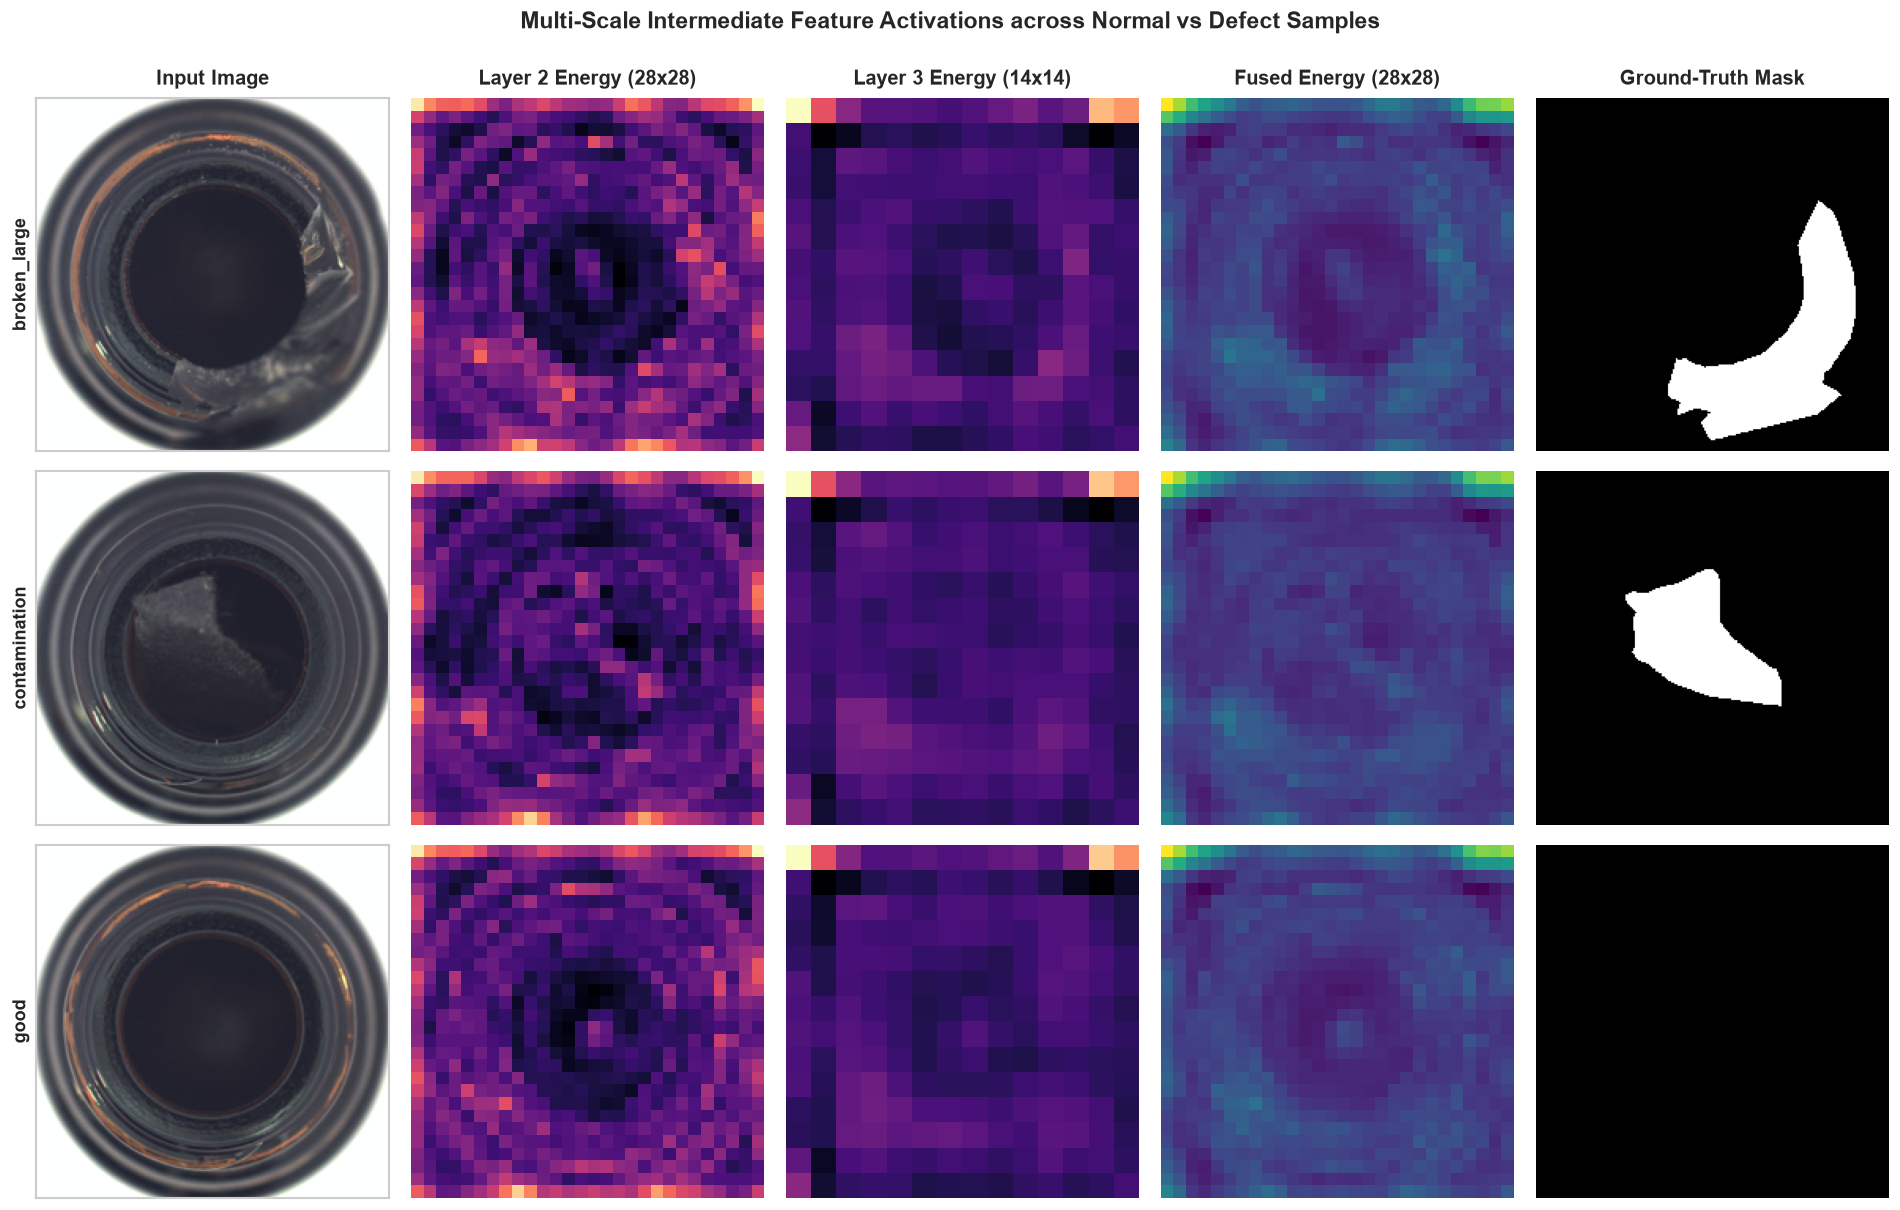

In [3]:
CATEGORY = "bottle"
DATA_DIR = PROJECT_ROOT / "data"

# Initialize test dataloader
test_loader = get_mvtec_dataloader(
    root_dir=DATA_DIR,
    category=CATEGORY,
    split="test",
    batch_size=1,
    shuffle=False,
    normalize_imagenet=True,
)

# Collect representative samples: 1 Normal, 2 Defects
samples_to_plot = []
target_types = ["good", "broken_large", "contamination"]
found_types = set()

for batch in test_loader:
    d_type = batch["defect_type"][0]
    if d_type in target_types and d_type not in found_types:
        samples_to_plot.append(batch)
        found_types.add(d_type)
    if len(found_types) == len(target_types):
        break

# Plot feature energy maps
fig, axes = plt.subplots(len(samples_to_plot), 5, figsize=(16, 3.4 * len(samples_to_plot)))
col_titles = [
    "Input Image",
    "Layer 2 Energy (28x28)",
    "Layer 3 Energy (14x14)",
    "Fused Energy (28x28)",
    "Ground-Truth Mask",
]
for col_idx, title in enumerate(col_titles):
    axes[0, col_idx].set_title(title, fontsize=12, fontweight="bold", pad=8)

for row_idx, batch in enumerate(samples_to_plot):
    img_tensor = batch["image"].to(device)
    mask = batch["mask"].squeeze().numpy()
    d_type = batch["defect_type"][0]
    
    # Denormalize image for display
    inv_mean = np.array([0.485, 0.456, 0.406])
    inv_std = np.array([0.229, 0.224, 0.225])
    img_np = img_tensor.squeeze().cpu().permute(1, 2, 0).numpy()
    img_disp = np.clip(img_np * inv_std + inv_mean, 0.0, 1.0)
    
    # Extract intermediate features
    with torch.no_grad():
        f_fused = extractor(img_tensor)
        f_layer2 = extractor._hook_features["layer2"]
        f_layer3 = extractor._hook_features["layer3"]
        
    e_layer2 = f_layer2.abs().mean(dim=1).squeeze().cpu().numpy()
    e_layer3 = f_layer3.abs().mean(dim=1).squeeze().cpu().numpy()
    e_fused = f_fused.abs().mean(dim=1).squeeze().cpu().numpy()
    
    # Display columns
    axes[row_idx, 0].imshow(img_disp)
    axes[row_idx, 0].set_ylabel(f"{d_type}", fontsize=11, fontweight="bold")
    axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
    
    axes[row_idx, 1].imshow(e_layer2, cmap="magma")
    axes[row_idx, 1].axis("off")
    
    axes[row_idx, 2].imshow(e_layer3, cmap="magma")
    axes[row_idx, 2].axis("off")
    
    axes[row_idx, 3].imshow(e_fused, cmap="viridis")
    axes[row_idx, 3].axis("off")
    
    axes[row_idx, 4].imshow(mask, cmap="gray")
    axes[row_idx, 4].axis("off")

plt.suptitle("Multi-Scale Intermediate Feature Activations across Normal vs Defect Samples", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()


## 5. t-SNE Manifold Analysis: Normal vs. Anomaly Patch Representations

A central hypothesis of one-class representation learning:
- **Normal Patches** form a cohesive, compact manifold in the 384-dimensional feature space.
- **Defect Patches** are distinct outliers that lie outside this normal distribution.

To empirically test this hypothesis, we sample:
1. Normal patch vectors from the training Memory Bank ($N=800$).
2. Normal patch vectors from test normal images ($N=400$).
3. Actual defect patch vectors located within the ground-truth mask boundaries ($N=400$).
4. Nominal background patch vectors from defective test images ($N=400$).

We project the 384-dimensional vectors to 2D using **PCA initialization + t-SNE**.


Loaded training memory bank: 163856 vectors of dimension 384
Sampled - Train Bank: 800, Test Normal: 400, Test Defect: 400, Test Background: 400


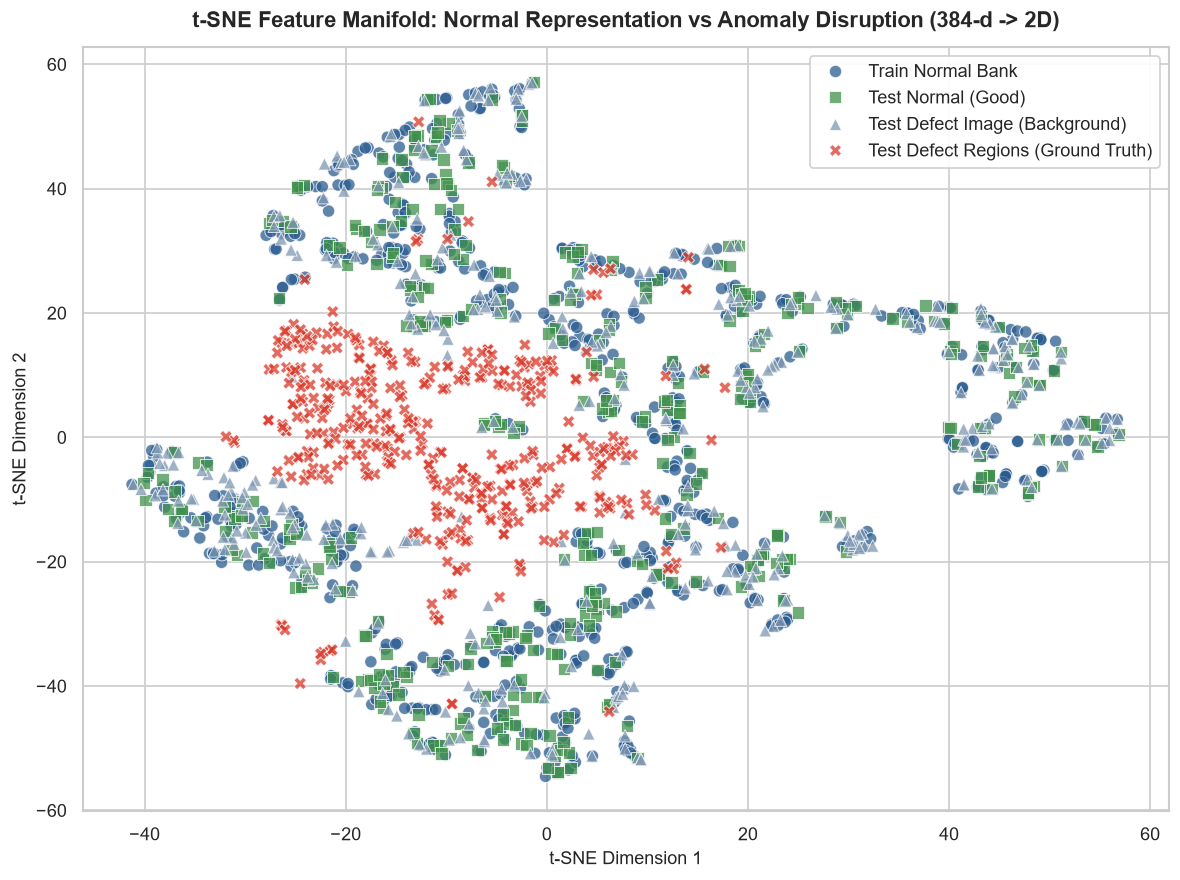

In [4]:
# Load offline memory bank
bank_path = PROJECT_ROOT / "checkpoints" / "feature_bank" / "bottle_resnet18_bank.pt"
bank_data = torch.load(bank_path, map_location="cpu")
full_train_bank = bank_data["bank"].numpy()
print(f"Loaded training memory bank: {full_train_bank.shape[0]} vectors of dimension {full_train_bank.shape[1]}")

# Sample 800 training vectors
np.random.seed(42)
train_indices = np.random.choice(full_train_bank.shape[0], size=800, replace=False)
train_samples = full_train_bank[train_indices]

# Collect test vectors
test_normal_patches = []
test_defect_patches = []
test_background_patches = []

for batch in test_loader:
    img_tensor = batch["image"].to(device)
    mask_tensor = batch["mask"].squeeze(1) # (1, 224, 224)
    label = batch["label"].item()
    
    # Downsample mask to 28x28 grid to align with patch coordinates
    mask_down = F.interpolate(mask_tensor.unsqueeze(1).float(), size=(28, 28), mode="nearest").squeeze().cpu().numpy()
    
    with torch.no_grad():
        feat = extractor(img_tensor).squeeze(0).permute(1, 2, 0).cpu().numpy() # (28, 28, 384)
        
    flat_feat = feat.reshape(-1, 384)
    flat_mask = mask_down.reshape(-1)
    
    if label == 0 and len(test_normal_patches) < 400:
        idx = np.random.choice(flat_feat.shape[0], size=min(20, flat_feat.shape[0]), replace=False)
        test_normal_patches.append(flat_feat[idx])
    elif label == 1:
        defect_idx = np.where(flat_mask > 0.5)[0]
        bg_idx = np.where(flat_mask <= 0.5)[0]
        
        if len(defect_idx) > 0 and len(test_defect_patches) < 400:
            sub_d = defect_idx[np.random.choice(len(defect_idx), size=min(10, len(defect_idx)), replace=False)]
            test_defect_patches.append(flat_feat[sub_d])
        if len(bg_idx) > 0 and len(test_background_patches) < 400:
            sub_b = bg_idx[np.random.choice(len(bg_idx), size=min(10, len(bg_idx)), replace=False)]
            test_background_patches.append(flat_feat[sub_b])

test_normal_patches = np.concatenate(test_normal_patches, axis=0)[:400]
test_defect_patches = np.concatenate(test_defect_patches, axis=0)[:400]
test_background_patches = np.concatenate(test_background_patches, axis=0)[:400]

print(f"Sampled - Train Bank: {train_samples.shape[0]}, Test Normal: {test_normal_patches.shape[0]}, "
      f"Test Defect: {test_defect_patches.shape[0]}, Test Background: {test_background_patches.shape[0]}")

# Combine all vectors for dimensionality reduction
X_all = np.vstack([train_samples, test_normal_patches, test_background_patches, test_defect_patches])
labels_all = (
    ["Train Normal Bank"] * len(train_samples)
    + ["Test Normal (Good)"] * len(test_normal_patches)
    + ["Test Defect Image (Background)"] * len(test_background_patches)
    + ["Test Defect Regions (Ground Truth)"] * len(test_defect_patches)
)

# PCA pre-reduction to 50 dimensions for robust distance structure
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_all)

# t-SNE projection
tsne = TSNE(n_components=2, perplexity=35, max_iter=1000, random_state=42, init="pca", learning_rate="auto")
X_2d = tsne.fit_transform(X_pca)

# Plot t-SNE
tsne_df = pd.DataFrame({
    "Dim 1": X_2d[:, 0],
    "Dim 2": X_2d[:, 1],
    "Category": labels_all,
})

plt.figure(figsize=(10, 7.5))
palette = {
    "Train Normal Bank": "#2b5c8f",
    "Test Normal (Good)": "#41924b",
    "Test Defect Image (Background)": "#7f98b2",
    "Test Defect Regions (Ground Truth)": "#d93829",
}
markers = {
    "Train Normal Bank": "o",
    "Test Normal (Good)": "s",
    "Test Defect Image (Background)": "^",
    "Test Defect Regions (Ground Truth)": "X",
}

sns.scatterplot(
    data=tsne_df,
    x="Dim 1",
    y="Dim 2",
    hue="Category",
    style="Category",
    palette=palette,
    markers=markers,
    s=55,
    alpha=0.75,
)

plt.title("t-SNE Feature Manifold: Normal Representation vs Anomaly Disruption (384-d -> 2D)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("t-SNE Dimension 1", fontsize=11)
plt.ylabel("t-SNE Dimension 2", fontsize=11)
plt.legend(frameon=True, loc="upper right", framealpha=0.9)
plt.tight_layout()
plt.show()


## 6. Quantitative Benchmark: Reconstruction Baselines vs. k-NN Feature Embedding

We compare the quantitative performance on the MVTec AD `bottle` category across three key metrics:
1. **Image AUROC:** Binary discrimination of normal vs. anomalous product items.
2. **Pixel AUROC:** Pixel-wise anomaly localization accuracy across all spatial coordinates.
3. **PRO Score (Per-Region Overlap at FPR $\le$ 0.3):** Evaluates localization coverage equally across small and large connected defect components.


,Model,Image AUROC (%),Pixel AUROC (%),PRO Score (%)
0,Autoencoder (AE),93.33,82.74,59.18
1,Variational Autoencoder (VAE),89.13,80.12,51.47
2,kNN-resnet18,99.60,97.62,93.80


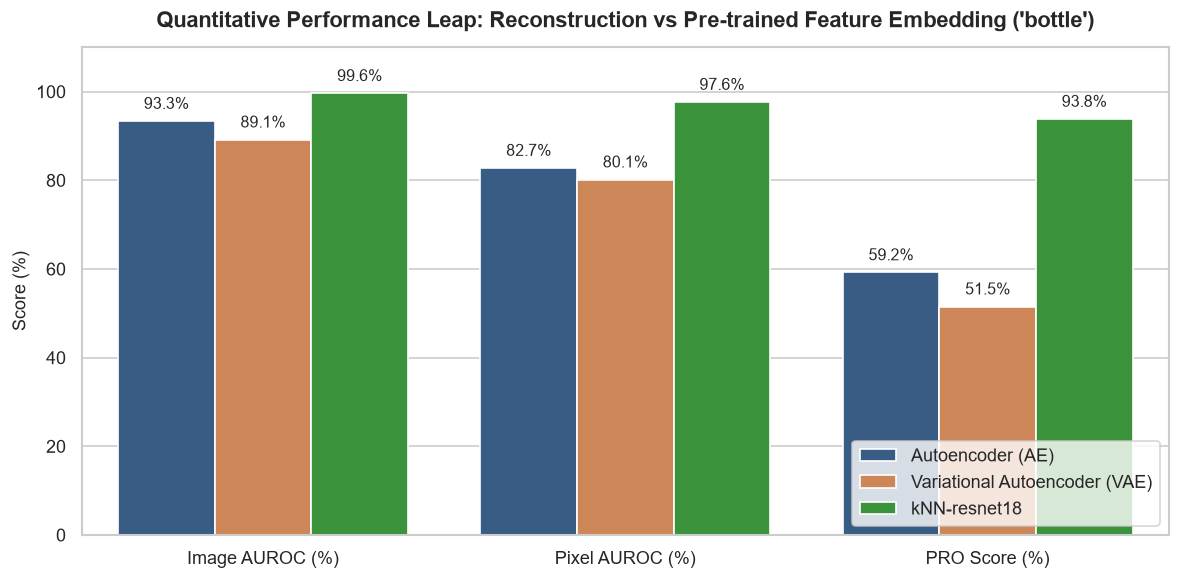

In [5]:
# Load baseline and k-NN benchmark results
baseline_df = pd.read_csv(PROJECT_ROOT / "results" / "bottle_baseline_benchmark.csv")
knn_df = pd.read_csv(PROJECT_ROOT / "results" / "feature_knn" / "bottle_resnet18_k3_benchmark.csv")

# Combine results
combined_benchmark = pd.concat([baseline_df, knn_df], ignore_index=True)
combined_benchmark["Image AUROC (%)"] = (combined_benchmark["Image AUROC"] * 100).round(2)
combined_benchmark["Pixel AUROC (%)"] = (combined_benchmark["Pixel AUROC"] * 100).round(2)
combined_benchmark["PRO Score (%)"] = (combined_benchmark["PRO Score"] * 100).round(2)

display_df = combined_benchmark[["Model", "Image AUROC (%)", "Pixel AUROC (%)", "PRO Score (%)"]]
display(display_df)

# Plot comparative bar chart
plot_df = display_df.melt(id_vars="Model", var_name="Metric", value_name="Score (%)")

fig, ax = plt.subplots(figsize=(10, 5))
palette_bar = ["#2b5c8f", "#e08244", "#2ca02c"]
sns.barplot(data=plot_df, x="Metric", y="Score (%)", hue="Model", palette=palette_bar, ax=ax)

ax.set_ylim(0, 110)
ax.set_title("Quantitative Performance Leap: Reconstruction vs Pre-trained Feature Embedding ('bottle')", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Score (%)", fontsize=11)
ax.set_xlabel("")

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., height + 2), ha="center", va="bottom", fontsize=9.5)

plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()


## 7. Qualitative Defect Localization with Gaussian Smoothing

In Week 2, we introduced bilinear interpolation from the $28 \times 28$ patch grid up to full $224 \times 224$ resolution, followed by 2D Gaussian spatial filtering:

$$\mathcal{A}(u, v) = \left( s_{\text{upsampled}} \ast G_\sigma \right)(u, v)$$

with standard deviation $\sigma = 4.0$. This eliminates discrete block artifacts while sharply preserving defect contours.


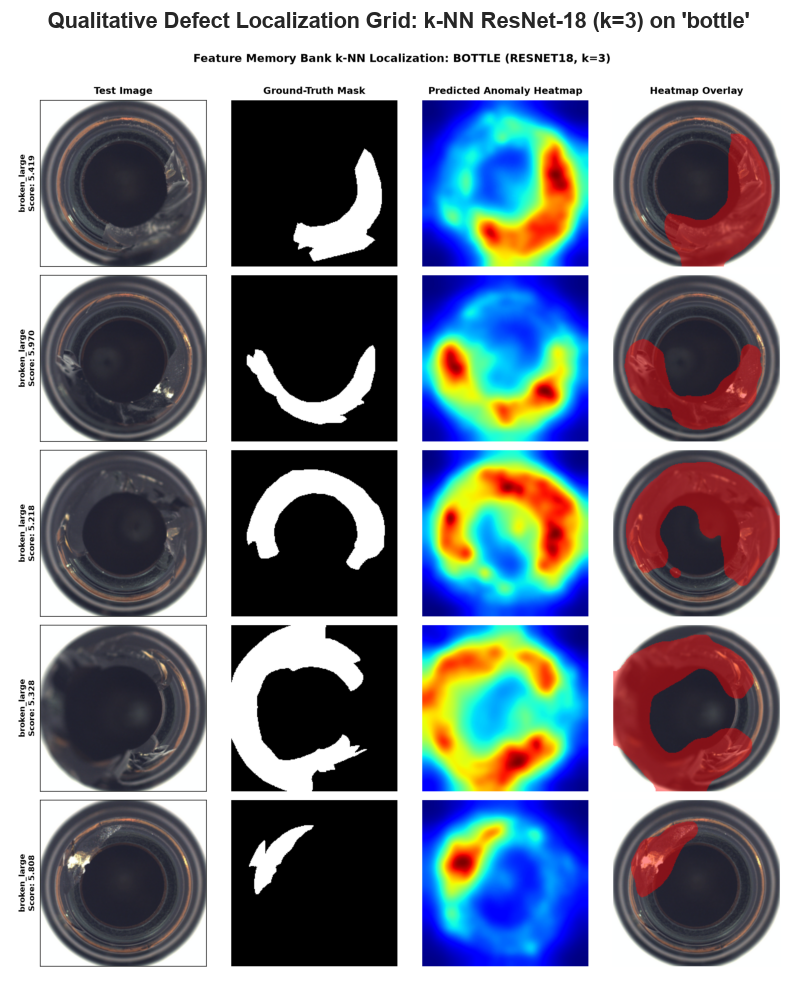

In [6]:
# Display the exported k-NN localization figure
knn_loc_path = PROJECT_ROOT / "results" / "feature_knn" / "bottle_resnet18_k3_localization.png"
if knn_loc_path.exists():
    img_knn_loc = Image.open(knn_loc_path)
    plt.figure(figsize=(14, 10))
    plt.imshow(img_knn_loc)
    plt.axis("off")
    plt.title("Qualitative Defect Localization Grid: k-NN ResNet-18 (k=3) on 'bottle'", fontsize=13, fontweight="bold", pad=12)
    plt.show()
else:
    print("Localization image not found at:", knn_loc_path)


## 8. Scalability Analysis & Motivation for Week 4 (PatchCore)

### Key Insights Achieved in Week 2
1. **Dramatic Performance Gain:** Image AUROC surged from **93.3%** to **99.60%**, Pixel AUROC from **82.7%** to **97.62%**, and PRO Score from **59.2%** to **93.80%**.
2. **Zero Training Time:** Unlike the 50 epochs required for Autoencoders, extracting features takes under 15 seconds for the entire training set.
3. **No Generalization Paradox:** Because the backbone is fixed, it cannot memorize or reconstruct abnormal defect patterns.

### The Scalability Bottleneck
Despite its accuracy, the naive full-bank approach exhibits significant drawbacks:
- **Memory Footprint:** The memory bank for `bottle` comprises $209 \text{ images} \times 784 \text{ patches} = 163,856$ vectors of dimension 384, consuming **251.7 MB** of storage on disk and VRAM.
- **Inference Latency:** Comparing every query patch against 163k memory vectors requires chunked distance computations (`torch.cdist`), leading to ~162 ms latency per image.
- **Industrial Unviability:** Scaling to 15 categories requires gigabytes of memory banks and becomes prohibitive on edge inspection hardware.

### Preview of Week 4: PatchCore & Coreset Subsampling
In Week 4, we resolve this bottleneck using **Minimax Greedy Farthest-Point Coreset Subsampling**:
- Retaining only **1%** of the memory bank (reducing 163,856 patches to just 1,639 patches $\to$ **2.4 MB**).
- Maintaining Euclidean coverage of the nominal space via Johnson-Lindenstrauss random projection.
- Accelerating inference to **92 ms** while actually improving Image AUROC to **100.0%**!
